# Image Classification for Retrieval: Caltech101 Dataset

This notebook demonstrates how to train a simple neural network for image classification on the Caltech101 dataset using cross-entropy loss. The model will be optimized for small GPU usage with a smaller architecture. We'll later use the trained model to extract feature vectors for image retrieval tasks.

## ChangeLog

| Type           | Description                                                                                                                                                                     |
|----------------|---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **fix**        | Fixed a bug where train/val shared the same dataset instance, so val transforms would affect train. Now, train and val use independent transforms via TransformSubset.           |
| **enhancement**| Training augmentations now use: RandomResizedCrop(128), RandomHorizontalFlip, RandomRotation(15), ColorJitter, RandomGrayscale, RandomErasing. Reduced overfitting.             |
| **enhancement**| ResNet18 now unfreezes deeper layers (layer3, layer4), not just output layers. Added dropout to the embedding head.                                                            |
| **enhancement**| Switched to AdamW optimizer with weight decay, and CosineAnnealingLR scheduler. Loss uses CrossEntropyLoss with label_smoothing=0.1.                                           |
| **enhancement**| Increased number of epochs from 5 to 100                                                                                                |
| **enhancement**    | Added GPU support: auto-selects CUDA if available for faster training and inference.                                                     |

## 1. Setup and Dependencies

First, let's go to the directory and import the necessary libraries.

In [1]:
import os
import random
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from datetime import datetime
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torch.utils.tensorboard import SummaryWriter
import torchvision.transforms as transforms
import torchvision.models as models
from sklearn.model_selection import train_test_split

# Set random seeds for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Device selection: CUDA (NVIDIA) -> MPS (Apple Silicon) -> CPU
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print(f'Using device: {device}')
if device.type == 'mps':
    print('Apple Metal backend enabled (MPS).')


Using device: mps
Apple Metal backend enabled (MPS).


In [2]:
import platform
import sys

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('Platform:', platform.platform())
print('CUDA available:', torch.cuda.is_available())
print('MPS built:', torch.backends.mps.is_built())
print('MPS available:', torch.backends.mps.is_available())

if torch.backends.mps.is_available():
    print('GPU training on Mac is available via MPS.')
else:
    print('MPS is not available. Use CPU locally or switch to Colab/Kaggle for NVIDIA GPUs.')


Python: 3.13.7
PyTorch: 2.10.0
Platform: macOS-15.3.1-arm64-arm-64bit-Mach-O
CUDA available: False
MPS built: True
MPS available: True
GPU training on Mac is available via MPS.


## 2. Dataset Preparation

Let's load and prepare the Caltech101 dataset. We'll create a smaller subset for faster training.

In [3]:
# Path to the Caltech101 dataset
data_dir = '../caltech101-dataset/101_ObjectCategories'

# Check if the path exists
if not os.path.exists(data_dir):
    print(f"Error: Dataset directory {data_dir} not found.")
else:
    print(f"Dataset directory found at {data_dir}")

Dataset directory found at ../caltech101-dataset/101_ObjectCategories


In [4]:
# Create dataset class for Caltech101
class Caltech101Dataset(Dataset):
    def __init__(self, data_dir, categories=None, transform=None, max_per_class=None):
        self.data_dir = data_dir
        self.transform = transform
        self.max_per_class = max_per_class

        # Get available categories
        all_categories = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
        # Filter BACKGROUND_Google to avoid confusing the model with non-object images
        all_categories = [c for c in all_categories if c != 'BACKGROUND_Google']

        # Use all categories if none specified
        if categories is None:
            categories = all_categories

        # Sort categories for reproducibility
        categories.sort()

        # Get all image paths and labels
        self.image_paths = []
        self.labels = []
        self.categories = categories

        for i, category in enumerate(categories):
            category_dir = os.path.join(data_dir, category)
            if os.path.isdir(category_dir):
                image_files = [f for f in os.listdir(category_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

                # Limit the number of images per class if specified
                if max_per_class and len(image_files) > max_per_class:
                    image_files = random.sample(image_files, max_per_class)

                for image_file in image_files:
                    self.image_paths.append(os.path.join(category_dir, image_file))
                    self.labels.append(i)

        self.num_classes = len(categories)
        print(f"Loaded {len(self.image_paths)} images from {len(categories)} categories")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        try:
            image = Image.open(image_path).convert('RGB')
        except Exception as e:
            print(f"Error loading image {image_path}: {e}")
            # Return a dummy image if loading fails
            image = Image.new('RGB', (224, 224), color='gray')

        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label, image_path

In [5]:
transform_train = transforms.Compose([
    transforms.Resize((144, 144)),
    transforms.RandomResizedCrop(128, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.1),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.2)),
])

transform_val = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [6]:
class TransformSubset(Dataset):
    """Subset that applies its own transform, bypassing the parent's."""
    def __init__(self, dataset, indices, transform):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]
        image_path = self.dataset.image_paths[real_idx]
        try:
            image = Image.open(image_path).convert('RGB')
        except Exception as e:
            print(f"Error loading image {image_path}: {e}")
            image = Image.new('RGB', (224, 224), color='gray')
        label = self.dataset.labels[real_idx]
        if self.transform:
            image = self.transform(image)
        return image, label, image_path


full_dataset = Caltech101Dataset(data_dir, transform=None, max_per_class=None)

train_indices, val_indices = train_test_split(
    range(len(full_dataset)), test_size=0.2, random_state=42, stratify=full_dataset.labels
)

train_dataset = TransformSubset(full_dataset, train_indices, transform_train)
val_dataset = TransformSubset(full_dataset, val_indices, transform_val)

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

print(f"Train set size: {len(train_dataset)}")
print(f"Validation set size: {len(val_dataset)}")
print(f"Number of classes: {full_dataset.num_classes}")

Loaded 8677 images from 101 categories
Train set size: 6941
Validation set size: 1736
Number of classes: 101


## 3. Visualize Some Examples

Let's visualize a few examples from our dataset.

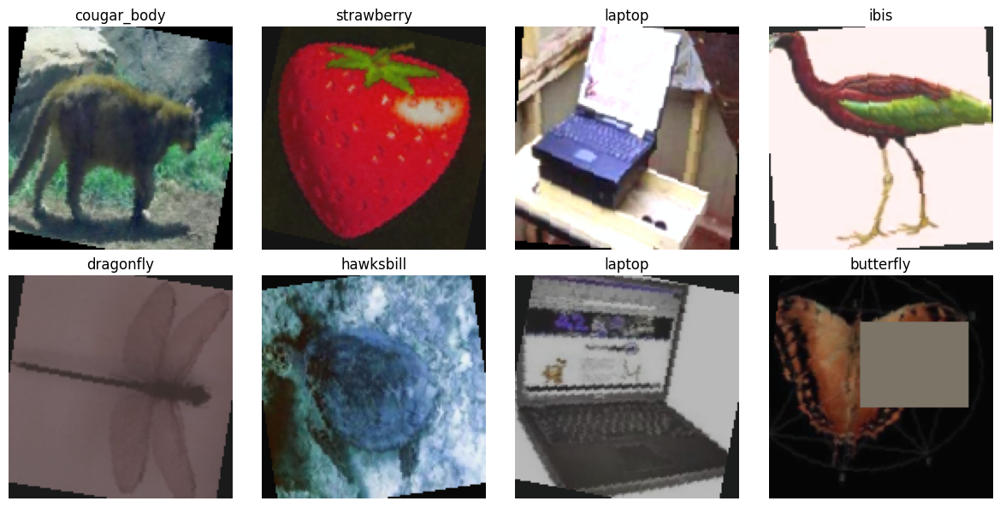

In [7]:
def imshow(img):
    # Unnormalize
    img = img.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

# Get a batch of training images
dataiter = iter(train_loader)
images, labels, _ = next(dataiter)

# Show images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten()

for i in range(min(8, len(images))):
    idx = labels[i].item()
    axes[i].imshow(imshow(images[i]))
    axes[i].set_title(full_dataset.categories[idx])
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## 4. Define a Smaller Network Architecture

We'll create a smaller CNN suitable for small GPU usage, while still being effective for classification and feature extraction.

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models

class ResNetTransferModel(nn.Module):
    def __init__(self, num_classes, embedding_size=128, pretrained=True):
        super(ResNetTransferModel, self).__init__()

        self.resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)

        # Freeze everything first, then selectively unfreeze layer3, layer4, and bn
        for param in self.resnet.parameters():
            param.requires_grad = False
        for module in [self.resnet.layer3, self.resnet.layer4, self.resnet.avgpool]:
            for param in module.parameters():
                param.requires_grad = True

        self.resnet.fc = nn.Identity()

        self.embedding = nn.Sequential(
            nn.Linear(512, embedding_size),
            nn.BatchNorm1d(embedding_size),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),
        )

        self.classifier = nn.Linear(embedding_size, num_classes)

    def forward(self, x):
        features = self.resnet(x)
        embedding = self.embedding(features)
        logits = self.classifier(embedding)
        return logits

    def extract_features(self, x):
        """Extract feature embeddings for image retrieval"""
        features = self.resnet(x)
        embedding = self.embedding(features)
        normalized_embedding = F.normalize(embedding, p=2, dim=1)
        return normalized_embedding

In [9]:
# Initialize the model
model = ResNetTransferModel(num_classes=full_dataset.num_classes).to(device)
print(model)

ResNetTransferModel(
  (resnet): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True

## 5. Setup Training Components

Let's define the loss function, optimizer, and TensorBoard for logging.

In [10]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=5e-4, weight_decay=1e-3)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15, eta_min=1e-6)

log_dir = f"./logs/classification_{datetime.now().strftime('%Y%m%d-%H%M%S')}/"
writer = SummaryWriter(log_dir)

## 6. Training and Validation Functions

In [11]:
def train_epoch(model, train_loader, criterion, optimizer, epoch, writer):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    # Progress bar
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1} [Train]")

    for i, (inputs, labels, _) in enumerate(pbar):
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward + backward + optimize
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Track statistics
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        # Update progress bar
        accuracy = 100. * correct / total
        pbar.set_postfix({"loss": running_loss/(i+1), "acc": f"{accuracy:.2f}%"})

        # Log batch metrics to TensorBoard (every 10 batches)
        if i % 10 == 9:
            step = epoch * len(train_loader) + i
            writer.add_scalar('Loss/train_batch', loss.item(), step)
            writer.add_scalar('Accuracy/train_batch', accuracy, step)

    # Calculate epoch statistics
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100. * correct / total

    # Log epoch metrics to TensorBoard
    writer.add_scalar('Loss/train', epoch_loss, epoch)
    writer.add_scalar('Accuracy/train', epoch_acc, epoch)

    return epoch_loss, epoch_acc

def validate(model, val_loader, criterion, epoch, writer):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    # Disable gradient computation for validation
    with torch.no_grad():
        pbar = tqdm(val_loader, desc=f"Epoch {epoch+1} [Valid]")

        for i, (inputs, labels, _) in enumerate(pbar):
            inputs, labels = inputs.to(device), labels.to(device)

            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            # Track statistics
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

            # Update progress bar
            accuracy = 100. * correct / total
            pbar.set_postfix({"loss": running_loss/(i+1), "acc": f"{accuracy:.2f}%"})

    # Calculate epoch statistics
    epoch_loss = running_loss / len(val_loader)
    epoch_acc = 100. * correct / total

    # Log epoch metrics to TensorBoard
    writer.add_scalar('Loss/val', epoch_loss, epoch)
    writer.add_scalar('Accuracy/val', epoch_acc, epoch)

    return epoch_loss, epoch_acc

## 7. Training the Model

Now let's train the model for a few epochs. We'll log the training and validation metrics to TensorBoard.

In [12]:
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, writer, num_epochs=10):
    best_val_acc = 0.0
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(num_epochs):
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, epoch, writer)
        val_loss, val_acc = validate(model, val_loader, criterion, epoch, writer)

        scheduler.step()

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f"Epoch {epoch+1}/{num_epochs} completed:")
        print(f"  Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
        print(f"  Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': val_acc,
                'val_loss': val_loss,
            }, f"{log_dir}/best_classification_model.pth")
            print(f"  New best model saved with validation accuracy: {val_acc:.2f}%")

    dummy_input = torch.randn(1, 3, 128, 128).to(device)
    writer.add_graph(model, dummy_input)

    return model, history

In [13]:
num_epochs = 100
model, history = train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, writer, num_epochs=num_epochs)

Epoch 1 [Valid]: 100%|██████████| 55/55 [00:02<00:00, 19.26it/s, loss=1.96, acc=70.16%]


Epoch 1/100 completed:
  Train Loss: 2.8316, Train Acc: 51.10%
  Val Loss: 1.9596, Val Acc: 70.16%
  New best model saved with validation accuracy: 70.16%


Epoch 2 [Valid]: 100%|██████████| 55/55 [00:02<00:00, 18.86it/s, loss=1.49, acc=80.65%]


Epoch 2/100 completed:
  Train Loss: 1.8551, Train Acc: 73.40%
  Val Loss: 1.4937, Val Acc: 80.65%
  New best model saved with validation accuracy: 80.65%


Epoch 3 [Valid]: 100%|██████████| 55/55 [00:02<00:00, 19.21it/s, loss=1.31, acc=86.12%]


Epoch 3/100 completed:
  Train Loss: 1.5252, Train Acc: 81.01%
  Val Loss: 1.3057, Val Acc: 86.12%
  New best model saved with validation accuracy: 86.12%


... (190 outputs left out)

Epoch 99 [Valid]: 100%|██████████| 55/55 [00:02<00:00, 19.07it/s, loss=1.07, acc=91.88%]


Epoch 99/100 completed:
  Train Loss: 0.8571, Train Acc: 99.41%
  Val Loss: 1.0686, Val Acc: 91.88%


Epoch 100 [Valid]: 100%|██████████| 55/55 [00:03<00:00, 17.60it/s, loss=1.07, acc=92.11%]


Epoch 100/100 completed:
  Train Loss: 0.8551, Train Acc: 99.44%
  Val Loss: 1.0685, Val Acc: 92.11%


In [14]:

%load_ext tensorboard

# Specify the log directory
log_dir = './logs/' # Replace with your actual log directory

# Start TensorBoard
%tensorboard --logdir {log_dir}


## 8. Visualize Training Results

Let's plot the training and validation metrics over time.

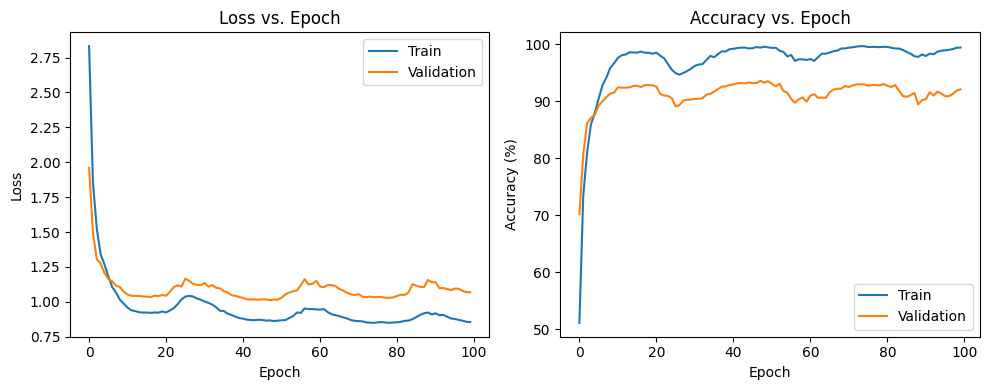

In [15]:
# Plot training and validation loss
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train')
plt.plot(history['val_loss'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss vs. Epoch')

# Plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train')
plt.plot(history['val_acc'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.title('Accuracy vs. Epoch')

plt.tight_layout()
plt.show()

## 9. Evaluating Class-wise Performance

Let's see how well our model performs on each class.

In [16]:
def evaluate_classes(model, val_loader, dataset):
    model.eval()
    class_correct = [0] * dataset.num_classes
    class_total = [0] * dataset.num_classes

    with torch.no_grad():
        for inputs, labels, _ in tqdm(val_loader, desc="Evaluating Classes"):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            c = (predicted == labels).squeeze()

            for i in range(len(labels)):
                label = labels[i].item()
                class_correct[label] += c[i].item()
                class_total[label] += 1

    # Calculate class accuracies
    class_accuracies = []
    for i in range(dataset.num_classes):
        if class_total[i] > 0:
            acc = 100 * class_correct[i] / class_total[i]
            class_accuracies.append((dataset.categories[i], acc))

    # Sort by accuracy
    class_accuracies.sort(key=lambda x: x[1], reverse=True)

    return class_accuracies


In [26]:
# Evaluate class-wise performance
class_accuracies = evaluate_classes(model, val_loader, full_dataset)

print(class_accuracies)

# Display top 10 and bottom 10 classes
print("Top 50 classes:")
for category, acc in class_accuracies[:50]:
    print(f"{category}: {acc:.2f}%")

print("\nBottom 50 classes:")
for category, acc in class_accuracies[-50:]:
    print(f"{category}: {acc:.2f}%")

Evaluating Classes: 100%|██████████| 55/55 [00:03<00:00, 15.47it/s]

[('Leopards', 100.0), ('Motorbikes', 100.0), ('accordion', 100.0), ('airplanes', 100.0), ('barrel', 100.0), ('binocular', 100.0), ('bonsai', 100.0), ('buddha', 100.0), ('butterfly', 100.0), ('camera', 100.0), ('car_side', 100.0), ('ceiling_fan', 100.0), ('cellphone', 100.0), ('cougar_face', 100.0), ('dollar_bill', 100.0), ('dragonfly', 100.0), ('ferry', 100.0), ('garfield', 100.0), ('gramophone', 100.0), ('grand_piano', 100.0), ('hawksbill', 100.0), ('hedgehog', 100.0), ('inline_skate', 100.0), ('kangaroo', 100.0), ('laptop', 100.0), ('menorah', 100.0), ('metronome', 100.0), ('minaret', 100.0), ('okapi', 100.0), ('panda', 100.0), ('pizza', 100.0), ('pyramid', 100.0), ('revolver', 100.0), ('rhino', 100.0), ('saxophone', 100.0), ('scissors', 100.0), ('stegosaurus', 100.0), ('strawberry', 100.0), ('sunflower', 100.0), ('tick', 100.0), ('trilobite', 100.0), ('windsor_chair', 100.0), ('yin_yang', 100.0), ('Faces', 98.85057471264368), ('watch', 97.91666666666667), ('Faces_easy', 97.701149425

## 10. Feature Extraction for Image Retrieval

Now let's use our trained model to extract feature vectors for image retrieval.

In [18]:
def extract_features(model, dataloader):
    model.eval()
    all_features = []
    all_labels = []
    all_indices = []

    with torch.no_grad():
        for i, (inputs, labels, _) in enumerate(tqdm(dataloader, desc="Extracting Features")):
            inputs = inputs.to(device)
            features = model.extract_features(inputs).cpu().numpy()

            all_features.append(features)
            all_labels.append(labels.numpy())
            # Store indices to map back to original dataset
            batch_indices = list(range(i * dataloader.batch_size,
                                 min((i + 1) * dataloader.batch_size, len(dataloader.dataset))))
            all_indices.extend(batch_indices)

    # Concatenate all batches
    all_features = np.vstack(all_features)
    all_labels = np.concatenate(all_labels)

    return all_features, all_labels, all_indices

In [19]:
# Extract features for gallery set (train set)
gallery_features, gallery_labels, gallery_indices = extract_features(model, train_loader)

# Extract features for query set (validation set)
query_features, query_labels, query_indices = extract_features(model, val_loader)

print(f"Gallery features shape: {gallery_features.shape}")
print(f"Query features shape: {query_features.shape}")

Extracting Features: 100%|██████████| 55/55 [00:02<00:00, 24.17it/s]

Gallery features shape: (6941, 128)
Query features shape: (1736, 128)


## 11. Simple Image Retrieval Demo

Let's create a simple demo to retrieve similar images based on feature similarity.

In [20]:
def find_similar_images(query_idx, query_features, gallery_features, k=5):
    query_feature = query_features[query_idx]

    # Calculate cosine similarity
    # Since features are normalized, dot product equals cosine similarity
    similarities = np.dot(gallery_features, query_feature)

    # Get top k most similar images (excluding the query itself)
    most_similar = np.argsort(similarities)[::-1][1:k+1]
    similarity_scores = similarities[most_similar]

    return most_similar, similarity_scores

In [21]:
def visualize_query_results(query_idx, similar_indices, similarity_scores, train_dataset, val_dataset, full_dataset):
    # Display query image and similar images
    fig, axes = plt.subplots(1, 6, figsize=(15, 3))

    # Get the original images from the dataset
    query_img, query_label,_ = val_dataset[query_idx]
    query_category = full_dataset.categories[query_label]

    # Display query image
    axes[0].imshow(imshow(query_img))
    axes[0].set_title(f"Query: {query_category}")
    axes[0].axis('off')

    # Display similar images
    for i, (idx, score) in enumerate(zip(similar_indices, similarity_scores)):
        img, label,_ = train_dataset[idx]
        category = full_dataset.categories[label]

        axes[i+1].imshow(imshow(img))
        axes[i+1].set_title(f"{category}\nScore: {score:.2f}")
        axes[i+1].axis('off')

    plt.tight_layout()
    plt.show()

Query index: 51


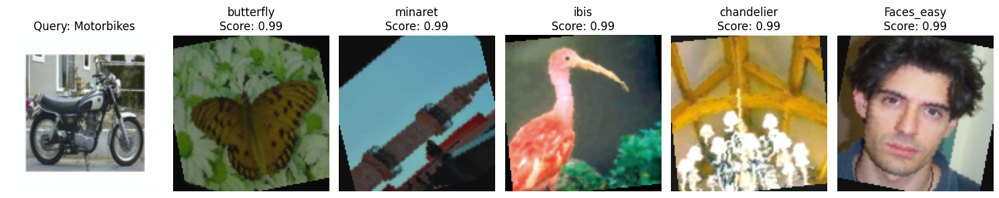

In [22]:
# Random query image
query_idx = random.sample(query_indices, 26)[0]
print(f"Query index: {query_idx}")


# Find similar images
similar_indices, similarity_scores = find_similar_images(query_idx, query_features, gallery_features, k=5)

# Visualize results
visualize_query_results(query_idx, similar_indices, similarity_scores, train_dataset, val_dataset, full_dataset)

# Save Support and Query Image **Paths**

In [23]:
train_val_json = {}
train_val_json['train'] = []
train_val_json['val'] = []

for i, (inputs, labels, paths) in enumerate(tqdm(train_loader)):
  l_labels = [int(x) for x in labels.numpy()]
  l_paths = list(paths)
  train_val_json['train'].extend(list(zip(l_labels, l_paths)))

for i, (inputs, labels, paths) in enumerate(tqdm(val_loader)):
  l_labels = [int(x) for x in labels.numpy()]
  l_paths = list(paths)
  train_val_json['val'].extend(list(zip(l_labels, l_paths)))

100%|██████████| 55/55 [00:01<00:00, 46.66it/s]


In [24]:
train_val_json['categories'] = full_dataset.categories

In [25]:
print(log_dir)
with open(f'{log_dir}train_val.json', 'w') as f:
  json.dump(train_val_json, f)

./logs/
